# Mendeley IoT Dataset — Unsupervised Anomaly Detection


Semi-supervised autoencoder for network intrusion detection: trained on benign traffic
only, evaluated on a balanced labeled test set (5000 benign / 5000 attack).

Part of the federated IDS project. This dataset serves as a **smoke test** —
the realistic evaluation is done on AIT Log Data Set V2.1.



https://data.mendeley.com/datasets/m8swht7tmn/1

## Project Description

### Goal:
- Build a **semi-supervised autoencoder** that learns what normal IoT traffic looks like,
then flags anything that reconstructs poorly as a potential intrusion. No attack labels
are used during training — only during evaluation.


### Pipeline
- **Data pre-processing (10%)** — feature selection, encoding, scaling
- **Feature selection (5%)** — rationale documented in the EDA section
- **Model comparison (25%)** — AE at multiple bottlenecks + Isolation Forest / One-Class SVM / supervised RF baselines
- **Hyperparameter tuning** — bottleneck sweep with AUC/F1 comparison
- **Over/underfitting analysis** — train vs validation gap per configuration



## 1. Setup & Imports:

### imports

In [37]:
import pickle
import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### paths

In [38]:
PROJECT_ROOT = Path("..").resolve()
DATA_DIR     = PROJECT_ROOT / "datasets" / "mendeley" / "Datasets"
STORE_DIR    = PROJECT_ROOT / "datasets" / "processed"
STORE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Python: {sys.version.split()[0]}  ({sys.executable})")
print(f"Data:   {DATA_DIR}  exists: {DATA_DIR.exists()}")
print(f"Store:  {STORE_DIR}")

Python: 3.14.7  (/home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/fedora-venv/bin/python)
Data:   /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/mendeley/Datasets  exists: True
Store:  /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed


### setup

In [39]:
def set_seed(seed: int = 42) -> None:
    """Seed every RNG that affects training. Call at the start of any training run."""
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
    except ImportError:
        pass

set_seed(42)


# Pandas table display
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)



### Load dataset from CSV

In [40]:
datasets = {}

def save_datasets(name="datasets.pkl"):
    path = STORE_DIR / name
    with open(path, "wb") as f:
        pickle.dump(datasets, f)
    print(f"saved → {path}  ({path.stat().st_size / 1024**2:.2f} MB)")

def load_datasets(name="datasets.pkl"):
    with open(STORE_DIR / name, "rb") as f:
        return pickle.load(f)

In [41]:
# Load once, reuse everywhere
iot_train = pd.read_csv(DATA_DIR / "iot_devices_dataset_for_training.csv")
iot_test  = pd.read_csv(DATA_DIR / "iot_devices_dataset_for_testing.csv")

print(f"iot_train: {iot_train.shape}   (unlabeled, benign-only)")
print(f"iot_test:  {iot_test.shape}    (labeled, 50/50 benign/attack)")
print()
print("dtypes in iot_train:")
print(iot_train.dtypes.value_counts().to_string())

iot_train: (30000, 43)   (unlabeled, benign-only)
iot_test:  (10000, 46)    (labeled, 50/50 benign/attack)

dtypes in iot_train:
int64      30
str         7
float64     6


## 2. Data Exploration

### 2.1 Raw Data Overview

We start by inspecting the raw dataset before making any preprocessing decisions. This is important because it lets us understand the original structure of the data and identify possible issues such as missing values, identifiers, and variable types.

In [42]:
label_cols = [c for c in iot_test.columns if c not in iot_train.columns]
print("Columns present only in iot_test (label / taxonomy):")
for c in label_cols:
    print(f"  {c:15s} dtype={iot_test[c].dtype}  nunique={iot_test[c].nunique()}")


Columns present only in iot_test (label / taxonomy):
  attack          dtype=int64  nunique=2
  category        dtype=str  nunique=5
  subcategory     dtype=str  nunique=7


#### Check data balance

- `iot_train` — **only benign traffic**. The model learns what "normal" looks like.
- `iot_test` — **50/50 attack and benign**. Used for evaluation only.

The test set has 3 more columns than the training set: `attack` (binary target), `category` (5 classes), and `subcategory` (7 classes). Those must be dropped from the test features before modeling (done in the "Save Raw Dataset" cell below).

In [43]:
print(f"iot_test shape: {iot_test.shape}")
print(f"\nattack balance (fraction):")
print(iot_test["attack"].value_counts(normalize=True).round(4).to_string())

print(f"\ncategory distribution:")
print(iot_test["category"].value_counts().to_string())

print(f"\nsubcategory distribution:")
print(iot_test["subcategory"].value_counts().to_string())

iot_test shape: (10000, 46)

attack balance (fraction):
attack
0    0.5
1    0.5

category distribution:
category
Benign            5000
DoS               1875
DDoS              1250
Reconnaissance    1250
Theft              625

subcategory distribution:
subcategory
normal            5000
TCP               1250
UDP               1250
HTTP               625
OS_Fingerprint     625
Service_Scan       625
Keylogging         625


### Save Raw Dataset

In [44]:
LABEL_COLS = ["attack", "category", "subcategory"]

datasets["raw"] = {
    "X_train": iot_train.copy(),
    "X_test":  iot_test.drop(columns=LABEL_COLS).copy(),
    "y_test":  iot_test["attack"].copy(),
    "description": "Raw: unlabeled train; test with target+taxonomy dropped",
}

# Compare train and test column names and their order
assert list(datasets["raw"]["X_train"].columns) == list(datasets["raw"]["X_test"].columns), \
    "raw train/test columns must match"

for k, v in datasets["raw"].items():
    if hasattr(v, "shape"):
        print(f"  {k:10s} {v.shape}")

save_datasets()

  X_train    (30000, 43)
  X_test     (10000, 43)
  y_test     (10000,)
saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/datasets.pkl  (12.04 MB)


#### Feature overview and missing values

In [45]:
raw_X = datasets["raw"]["X_train"]

rows = []
for col in raw_X.columns:
    s = raw_X[col]
    row = {
        "column":      col,
        "dtype":       str(s.dtype),
        "missing":     int(s.isna().sum()),
        "cardinality": int(s.nunique()),
    }
    if pd.api.types.is_numeric_dtype(s):
        row["min"]  = float(s.min())
        row["max"]  = float(s.max())
        row["mean"] = round(float(s.mean()), 4)
    else:
        row["min"]  = None
        row["max"]  = None
        row["mean"] = None
    rows.append(row)

summary = pd.DataFrame(rows).sort_values("cardinality")
display(summary)

,column,dtype,missing,cardinality,min,max,mean
1,stime,str,0,1,NaN,NaN,NaN
3,flgs_number,int64,0,1,1.000000,1.00000,1.0000
12,state,str,0,1,NaN,NaN,NaN
13,state_number,int64,0,1,1.000000,1.00000,1.0000
29,TnBPSrcIP,int64,0,1,1.000000,1.00000,1.0000
30,TnBPDstIP,int64,0,1,1.000000,1.00000,1.0000
31,TnP_PSrcIP,int64,0,1,1.000000,1.00000,1.0000
40,AR_P_Proto_P_Dport,int64,0,1,1.000000,1.00000,1.0000
39,AR_P_Proto_P_Sport,int64,0,1,1.000000,1.00000,1.0000
38,N_IN_Conn_P_SrcIP,int64,0,1,1.000000,1.00000,1.0000


### Overview :

#### Group A - constants : 
- `AR_P_Proto_P_Dport` to `TnP_Per_Dport` (19 first rows).
- Also : `flgs_number`(numeric encoding of flgs), `state`, `state_number`, `stime`, `ltime`,
- Constant values
- not useful, dropped.


#### Group B -identifiers :
- `pkSeqID` and `seq`.
- Both are just row indices. Including them would let the model memorise row order rather than learn traffic structure. This is a classic data leakage trap.


#### Group C — High-cardinality categoricals :
- `saddr` : 6 source IPs — probably the 6 testbed devices.
- `daddr` :	348 destination IPs. Too many to one-hot, and they carry almost no generalisable signal.
- `sport` :	23,970 Source Ports. Drop or bucket. Almost every row has a unique source port (ephemeral ports). Bucket into ranges or drop.
- `flgs`  :	Only PA and U in the sample. Use the 2-value string; ignore the broken flgs_number.
- `proto` :	9 protocols (SMB, NTP, HTTPS, HTTP, etc.). One-hot into 9 features, or use proto_number (2 unique values = TCP 6 / UDP 17).


#### Group D — Redundant pairs, keep one of each.
- `sbytes` / `dbytes` : Both n_unique=2351, both min=150, max=2500	Identical distributions. Drop one.
- `spkts` / `dpkts`	: Both n_unique=24, both 2–25	Drop one.
- `srate` / `drate`	: Both n_unique=28268	Drop one.
- `bytes` = `sbytes` + `dbytes` (roughly)	bytes 300–5000, sbytes 150–2500	Keep bytes, drop the two components.

This symmetry is not accidental — it is a strong sign the dataset was synthetically constructed with mirrored source/destination features. Useful for smoke-testing a Flower pipeline, less realistic as intrusion data.


#### Group E — Genuinely informative features :
- `bytes` :	300–5000	total bytes in the flow
- `pkts` :	5–50	total packets in the flow
- `dur` :	0.1–2.5 s	flow duration
- `rate` :	123–48,765	packets per second
- `mean` :	6–1000	mean duration of aggregated sub-flows
- `min` :	40–60	minimum sub-flow duration
- `max` :	500–1000	maximum sub-flow duration
- `stddev` :	0.1–1.5	std-dev of sub-flow durations — 30,000 unique values, looks like noise
- `sum` :	300–5000	sum of sub-flow durations (highly correlated with bytes)
- `proto_number` :	6 or 17	TCP vs. UDP
- `dport` :	10 values	destination port (53, 80, 443, 445, 5683, …)
- `flgs` :	2 values	flow flags (PA, U)

-> those 10–14 features actually carry variation.
--> That gives you roughly 10–12 useful numeric features and 2 low-cardinality categoricals (proto, flgs, or use proto_number + dport and skip flgs).


#### Note :
- stime has n_unique = 1. Every row in the training file shares the same start timestamp.
- Either the training file is a very short capture, or data was synthetically generated or post-processed.
- This dataset has no temporal signal in the training split.
- This dataset can only be used as a smoke test for our Flower pipeline, not a realistic benchmark




### Feature selection - Cleaned dataset

In [46]:
CONSTANT_COLS = [c for c in iot_train.columns if iot_train[c].nunique() <= 1]
ID_COLS       = ["pkSeqID", "seq"]
HIGH_CARD     = ["saddr", "daddr", "sport"]
REDUNDANT     = ["sbytes", "dbytes", "spkts", "dpkts", "srate"]
DROP          = CONSTANT_COLS + ID_COLS + HIGH_CARD + REDUNDANT

datasets["cleaned"] = {
    "train_X": datasets["raw"]["X_train"].drop(columns=DROP, errors="ignore").copy(),
    "test_X":  datasets["raw"]["X_test"].drop(columns=DROP, errors="ignore").copy(),
    "test_y":  datasets["raw"]["y_test"].copy(),
    "description": "Cleaned: constants/IDs/high-card/redundant dropped",
}

assert list(datasets["cleaned"]["train_X"].columns) == list(datasets["cleaned"]["test_X"].columns), \
    "cleaned train/test columns must match"

print(f"Dropped {len(DROP)} columns; kept {datasets['cleaned']['train_X'].shape[1]}")
print(f"Kept: {datasets['cleaned']['train_X'].columns.tolist()}")
for k, v in datasets["cleaned"].items():
    if hasattr(v, "shape"):
        print(f"  {k:10s} {v.shape}")

save_datasets()

Dropped 28 columns; kept 15
Kept: ['flgs', 'proto', 'proto_number', 'dport', 'pkts', 'bytes', 'ltime', 'dur', 'mean', 'stddev', 'sum', 'min', 'max', 'rate', 'drate']
  train_X    (30000, 15)
  test_X     (10000, 15)
  test_y     (10000,)
saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/datasets.pkl  (16.17 MB)


### 2.3. EDA plots on cleaned data

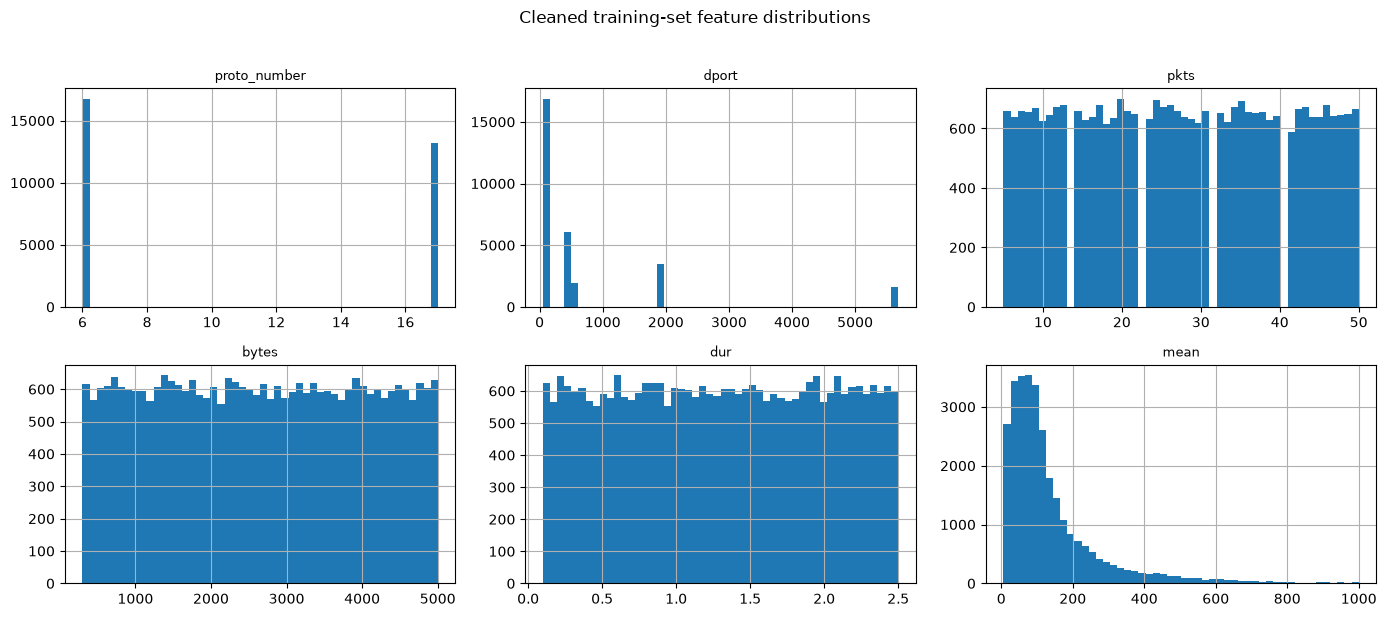

In [47]:
# ----- Distribution histograms -------
train_X = datasets["cleaned"]["train_X"]
num_cols = train_X.select_dtypes("number").columns.tolist()
to_plot = num_cols[:6]

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, col in zip(axes.ravel(), to_plot):
    train_X[col].hist(ax=ax, bins=50)
    ax.set_title(col, fontsize=9)
plt.suptitle("Cleaned training-set feature distributions", y=1.02)
plt.tight_layout()
plt.show()

#### Compare feature distributions: training (benign-dominant) vs. testing (labeled)

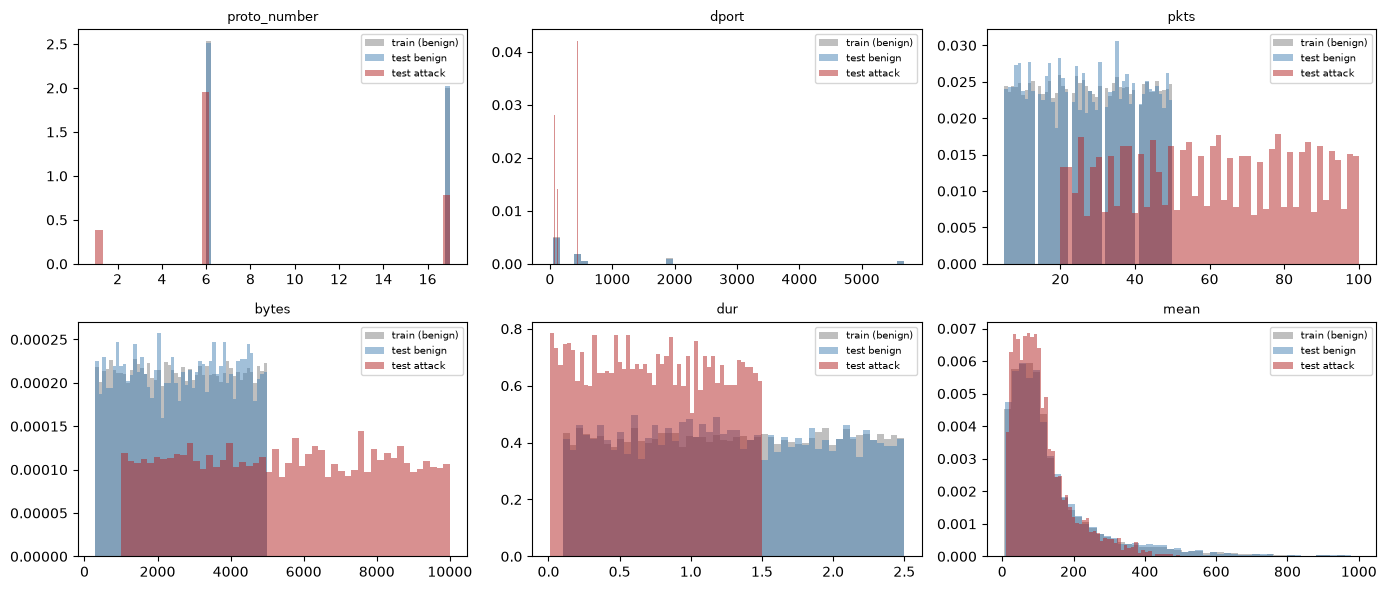

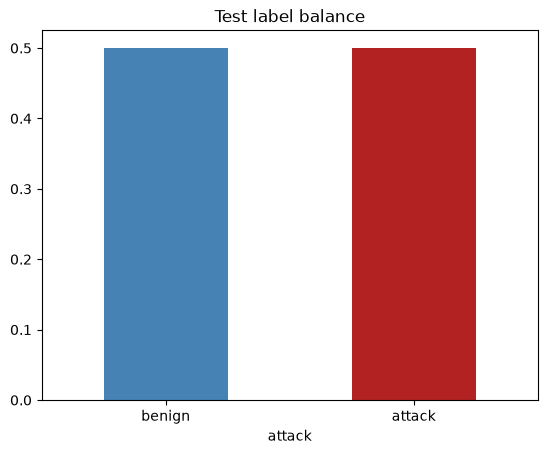

In [48]:
test_X = datasets["cleaned"]["test_X"]
y_test = datasets["cleaned"]["test_y"]

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, col in zip(axes.ravel(), to_plot):
    ax.hist(train_X[col], bins=50, alpha=0.5, label="train (benign)",
            density=True, color="grey")
    ax.hist(test_X.loc[y_test == 0, col], bins=50, alpha=0.5, label="test benign",
            density=True, color="steelblue")
    ax.hist(test_X.loc[y_test == 1, col], bins=50, alpha=0.5, label="test attack",
            density=True, color="firebrick")
    ax.set_title(col, fontsize=9)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

y_test.value_counts(normalize=True).plot(
    kind="bar", title="Test label balance", color=["steelblue", "firebrick"]
)
plt.xticks([0, 1], ["benign", "attack"], rotation=0)
plt.show()

#### Pytorch dataset

In [49]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Sanity check only — verifies PyTorch batching works before we build the model.
# The REAL model input (26 features after one-hot encoding) is defined in section 4.
X_num = datasets["cleaned"]["train_X"].select_dtypes("number").to_numpy(np.float32)
X_num = np.nan_to_num(X_num)

X_t = torch.from_numpy(X_num)
print(f"numeric-only subset: shape={X_t.shape}  dtype={X_t.dtype}")

loader = DataLoader(TensorDataset(X_t), batch_size=256, shuffle=True)
batch, = next(iter(loader))
print(f"one batch: shape={batch.shape}  ✓")

numeric-only subset: shape=torch.Size([30000, 12])  dtype=torch.float32
one batch: shape=torch.Size([256, 12])  ✓


## 3. Preprocessing

### 3.1 Dataset Splitting

In [50]:
from sklearn.model_selection import train_test_split

X_tr, X_val = train_test_split(
    datasets["cleaned"]["train_X"],
    train_size=0.9, 
    test_size=0.1,
    random_state=42,
)
print(f"train: {X_tr.shape}   valid: {X_val.shape}")

train: (27000, 15)   valid: (3000, 15)


### 3.2 Semi-supervised dataset

In [51]:
datasets["semisup"] = {
    "X_train": X_tr.copy(),                                # benign, training
    "X_valid": X_val.copy(),                               # benign, threshold
    "X_test":  datasets["cleaned"]["test_X"].copy(),       # mixed
    "y_test":  datasets["cleaned"]["test_y"].copy(),       # 0/1
    "description": "Semi-supervised: benign train/valid, mixed labeled test",
}

assert list(datasets["semisup"]["X_train"].columns) == \
       list(datasets["semisup"]["X_test"].columns), \
    "semisup train/test columns must match"

for name, contents in datasets.items():
    print(f"\n=== {name} ===")
    for k, v in contents.items():
        if hasattr(v, "shape"):
            print(f"  {k:10s} {v.shape}")

save_datasets()


=== raw ===
  X_train    (30000, 43)
  X_test     (10000, 43)
  y_test     (10000,)

=== cleaned ===
  train_X    (30000, 15)
  test_X     (10000, 15)
  test_y     (10000,)

=== semisup ===
  X_train    (27000, 15)
  X_valid    (3000, 15)
  X_test     (10000, 15)
  y_test     (10000,)
saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/datasets.pkl  (20.53 MB)


## 4. Encoding


- Categorical columns → one-hot (`handle_unknown="ignore"`).
- Numeric columns → `StandardScaler`.
- Both fit on **train only**, applied to valid and test.

In [52]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X_tr = datasets["semisup"]["X_train"]
X_va = datasets["semisup"]["X_valid"]
X_te = datasets["semisup"]["X_test"]

cat_cols = X_tr.select_dtypes("object").columns.tolist()
num_cols = [c for c in X_tr.columns if c not in cat_cols]
print(f"categorical: {cat_cols}")
print(f"numeric:     {num_cols}")

ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
tr_cat = ohe.fit_transform(X_tr[cat_cols])
va_cat = ohe.transform(X_va[cat_cols])
te_cat = ohe.transform(X_te[cat_cols])

tr_enc = np.hstack([X_tr[num_cols].to_numpy(np.float32), tr_cat]).astype(np.float32)
va_enc = np.hstack([X_va[num_cols].to_numpy(np.float32), va_cat]).astype(np.float32)
te_enc = np.hstack([X_te[num_cols].to_numpy(np.float32), te_cat]).astype(np.float32)

scaler = StandardScaler().fit(tr_enc)

datasets["encoded"] = {
    "X_train": scaler.transform(tr_enc).astype(np.float32),
    "X_valid": scaler.transform(va_enc).astype(np.float32),
    "X_test":  scaler.transform(te_enc).astype(np.float32),
    "y_test":  datasets["semisup"]["y_test"].to_numpy(),
    "feature_names": num_cols + ohe.get_feature_names_out(cat_cols).tolist(),
    "encoder": ohe,
    "scaler":  scaler,
    "description": "One-hot + standard-scale, fit on benign train",
}

for k, v in datasets["encoded"].items():
    if hasattr(v, "shape"):
        print(f"  {k:10s} {v.shape}")
print(f"features ({len(datasets['encoded']['feature_names'])}): "
      f"{datasets['encoded']['feature_names']}")

save_datasets()

categorical: ['flgs', 'proto', 'ltime']
numeric:     ['proto_number', 'dport', 'pkts', 'bytes', 'dur', 'mean', 'stddev', 'sum', 'min', 'max', 'rate', 'drate']
  X_train    (27000, 26)
  X_valid    (3000, 26)
  X_test     (10000, 26)
  y_test     (10000,)
features (26): ['proto_number', 'dport', 'pkts', 'bytes', 'dur', 'mean', 'stddev', 'sum', 'min', 'max', 'rate', 'drate', 'flgs_PA', 'flgs_U', 'proto_CoAP', 'proto_DNS', 'proto_HTTP', 'proto_HTTPS', 'proto_MQTT', 'proto_NTP', 'proto_RTSP', 'proto_SMB', 'proto_SSDP', 'ltime_2025-06-07 10:36:18', 'ltime_2025-06-07 10:36:19', 'ltime_2025-06-07 10:36:20']
saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/datasets.pkl  (24.57 MB)


/tmp/ipykernel_183201/3299023002.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_tr.select_dtypes("object").columns.tolist()


## 5. Autoencoder

#### Why AE ?
The training set is 100% benign. So the autoencoder learns the structure of normal traffic and only normal traffic. At inference:
- A benign flow comes in → matches the structure the model learned → low reconstruction error.
- An attack flow comes in → doesn't match any benign pattern → the model can't encode it → high reconstruction error.


Small symmetric autoencoder:
- input: encoded feature width (d~20)
- bottleneck: 4
- trained with MSE on benign training data

### Model builder 

In [53]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

def make_autoencoder(in_dim: int, bottleneck: int) -> nn.Module:
    """Symmetric autoencoder with a parameterised bottleneck width.

    Architecture: in_dim → 2·b → 4·b → b → 4·b → 2·b → in_dim
    where b = bottleneck.
    """
    class AE(nn.Module):
        def __init__(self):
            super().__init__()
            self.encoder = nn.Sequential(
                nn.Linear(in_dim,         2 * bottleneck), nn.ReLU(),
                nn.Linear(2 * bottleneck, 4 * bottleneck), nn.ReLU(),
                nn.Linear(4 * bottleneck, bottleneck),     nn.ReLU(),
            )
            self.decoder = nn.Sequential(
                nn.Linear(bottleneck,     4 * bottleneck), nn.ReLU(),
                nn.Linear(4 * bottleneck, 2 * bottleneck), nn.ReLU(),
                nn.Linear(2 * bottleneck, in_dim),
            )
        def forward(self, x):
            return self.decoder(self.encoder(x))
    return AE()


def train_autoencoder(X_tr, X_va, config: dict, verbose: bool = True):
    """Train one AE configuration. Returns (model, history, metrics_dict)."""
    set_seed(42)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model     = make_autoencoder(X_tr.shape[1], config["bottleneck"]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"])
    loss_fn   = nn.MSELoss()

    loader = DataLoader(
        TensorDataset(torch.from_numpy(X_tr)),
        batch_size=config["batch_size"], shuffle=True
    )
    X_va_t = torch.from_numpy(X_va).to(device)

    hist = {"train": [], "valid": []}
    best_val, best_state = float("inf"), None
    patience_counter = 0

    for epoch in range(config["epochs"]):
        model.train()
        running = 0.0
        for (batch,) in loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(batch), batch)
            loss.backward()
            optimizer.step()
            running += loss.item() * batch.size(0)
        tr_loss = running / len(loader.dataset)

        model.eval()
        with torch.no_grad():
            va_loss = loss_fn(model(X_va_t), X_va_t).item()

        hist["train"].append(tr_loss)
        hist["valid"].append(va_loss)

        if va_loss < best_val:
            best_val, best_state = va_loss, {k: v.clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= config.get("patience", 15):
                if verbose: print(f"  early stop at epoch {epoch}")
                break

        if verbose and (epoch % 10 == 0 or epoch == config["epochs"] - 1):
            print(f"  epoch {epoch:3d}  train={tr_loss:.5f}  valid={va_loss:.5f}")

    model.load_state_dict(best_state)

    return model, hist, {
        "bottleneck":    config["bottleneck"],
        "lr":            config["lr"],
        "batch_size":    config["batch_size"],
        "epochs_run":    len(hist["train"]),
        "best_val":      best_val,
        "final_train":   hist["train"][-1],
        "train_val_gap": hist["train"][-1] - best_val,
    }

### Train - one model at bottleneck n=24

We train one model here as example, later we'll run a hyperparam tuning for the bottleneck size, then use its output (which is 24) here aswell.

Training AE with bottleneck=24...
  epoch   0  train=0.66880  valid=0.34546
  epoch  10  train=0.00596  valid=0.00569
  epoch  20  train=0.00431  valid=0.00419
  epoch  30  train=0.00352  valid=0.00339
  epoch  40  train=0.00132  valid=0.00113
  epoch  50  train=0.00099  valid=0.00083
  epoch  60  train=0.00079  valid=0.00083
  epoch  70  train=0.00071  valid=0.00062
  epoch  80  train=0.00061  valid=0.00062
  epoch  90  train=0.00051  valid=0.00043
  epoch  99  train=0.00047  valid=0.00044
saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/autoencoder_main.pt


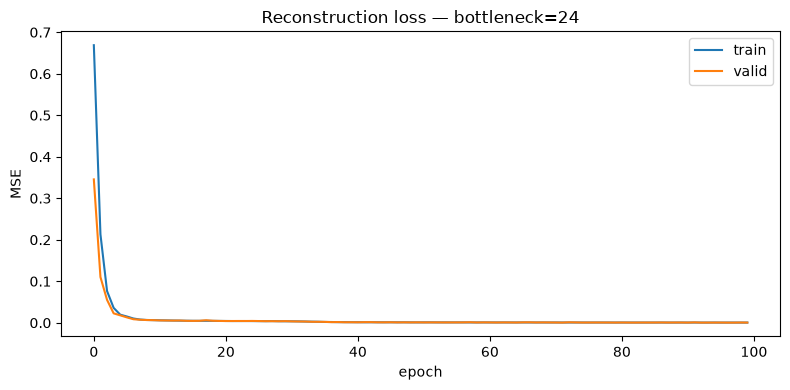

saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/datasets.pkl  (24.64 MB)


In [54]:
# ── Main configuration ───────────────────────────────────────────────────────
MAIN_CONFIG = {
    "bottleneck": 24,
    "lr":         1e-3,
    "batch_size": 256,
    "epochs":     100,
    "patience":   15,
}

X_tr = datasets["encoded"]["X_train"]
X_va = datasets["encoded"]["X_valid"]

print(f"Training AE with bottleneck={MAIN_CONFIG['bottleneck']}...")
model, hist, metrics = train_autoencoder(X_tr, X_va, MAIN_CONFIG)

# Save the trained model as a standalone .pt file (loadable without the pickle)
torch.save(model.state_dict(), STORE_DIR / "autoencoder_main.pt")
print(f"saved → {STORE_DIR / 'autoencoder_main.pt'}")

# Loss curves
plt.figure(figsize=(8, 4))
plt.plot(hist["train"], label="train")
plt.plot(hist["valid"], label="valid")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend()
plt.title(f"Reconstruction loss — bottleneck={MAIN_CONFIG['bottleneck']}")
plt.tight_layout(); plt.show()

# Store metrics for the comparison table later
datasets["autoencoder"] = {
    "model_state":   model.state_dict(),
    "in_dim":        X_tr.shape[1],
    "hist":          hist,
    "config":        MAIN_CONFIG,
    "train_val_gap": metrics["train_val_gap"],
}
save_datasets()

## 6. Threshold & Evaluation

The AE isn't a classifier, it only outputs a reconstruction. What construction error threshold do we choose to determine if we have an "attack" or a "bening" state ?

ex.
```bash
Row 1 (benign):   error = 0.15
Row 2 (attack):   error = 1.80
Row 3 (benign):   error = 0.22
Row 4 (attack):   error = 2.10
Row 5 (benign):   error = 0.08
...
```

What error value is greater than 95% of these?
-> this is the value we'll use.


Threshold = 95th percentile of reconstruction error on benign valid (5% FPR target).
Predict attack if error > threshold.

threshold = 0.00092

Confusion matrix:
[[4742  258]
 [1083 3917]]

Classification report:
              precision    recall  f1-score   support

      benign       0.81      0.95      0.88      5000
      attack       0.94      0.78      0.85      5000

    accuracy                           0.87     10000
   macro avg       0.88      0.87      0.86     10000
weighted avg       0.88      0.87      0.86     10000

ROC-AUC: 0.8860

Threshold sensitivity:
  percentile    threshold      FPR   recall  precision       F1
   85.0%        0.00057   14.98%   81.48%     84.47%    0.829
   90.0%        0.00070   10.16%   80.32%     88.77%    0.843
   95.0%        0.00092    5.16%   78.34%     93.82%    0.854
   97.0%        0.00113    3.22%   76.86%     95.98%    0.854
   99.0%        0.00172    1.18%   73.82%     98.43%    0.844
   99.5%        0.00227    0.52%   71.62%     99.28%    0.832


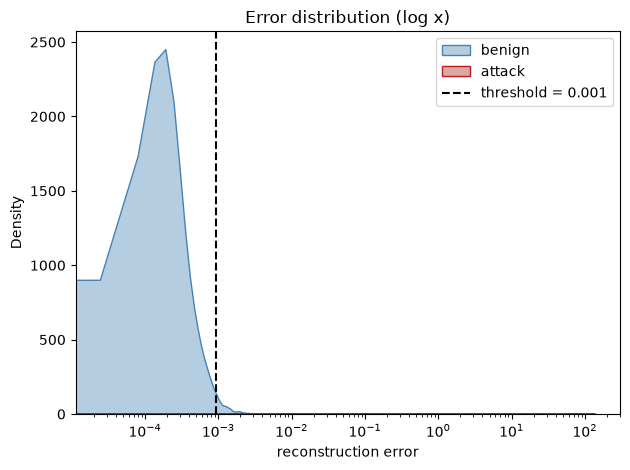

saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/datasets.pkl  (24.77 MB)


In [55]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

def recon_errors(m, X):
    m.eval()
    with torch.no_grad():
        X_t = torch.from_numpy(X)
        return ((m(X_t) - X_t) ** 2).mean(dim=1).numpy()

# Compute the reconstruction error for the test set (5000 benign / 5000 attack)
val_err  = recon_errors(model, datasets["encoded"]["X_valid"])
test_err = recon_errors(model, datasets["encoded"]["X_test"])    # apply threshold to test set

# Select the error at the 95th percentile
THRESHOLD = np.percentile(val_err, 95)
print(f"threshold = {THRESHOLD:.5f}")

# CLASSIFICATION
y_test = datasets["encoded"]["y_test"]
y_pred = (test_err > THRESHOLD).astype(int)    # apply theshold, convert to boolean (classification) 

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["benign", "attack"]))
print(f"ROC-AUC: {roc_auc_score(y_test, test_err):.4f}")



# Threshold sensitivity — FPR / recall trade-off 
print("\nThreshold sensitivity:")
print(f"{'percentile':>12} {'threshold':>12} {'FPR':>8} {'recall':>8} {'precision':>10} {'F1':>8}")
for pct in [85, 90, 95, 97, 99, 99.5]:
    thr = np.percentile(val_err, pct)
    yp  = (test_err > thr).astype(int)
    tn = ((yp == 0) & (y_test == 0)).sum()
    fp = ((yp == 1) & (y_test == 0)).sum()
    fn = ((yp == 0) & (y_test == 1)).sum()
    tp = ((yp == 1) & (y_test == 1)).sum()
    fpr  = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    print(f"  {pct:>5.1f}%   {thr:>12.5f}  {fpr:>7.2%}  {rec:>7.2%}  {prec:>9.2%}  {f1:>7.3f}")






# Plots
import seaborn as sns
sns.kdeplot(test_err[y_test == 0], label="benign", fill=True, alpha=0.4, color="steelblue")
sns.kdeplot(test_err[y_test == 1], label="attack", fill=True, alpha=0.4, color="firebrick")
plt.axvline(THRESHOLD, color="black", linestyle="--", label=f"threshold = {THRESHOLD:.3f}")
plt.xscale("log")
plt.xlabel("reconstruction error"); plt.legend(); plt.title("Error distribution (log x)")
plt.tight_layout(); plt.show()


# Save into datasets
datasets["autoencoder"].update({
    "threshold":   THRESHOLD,
    "val_errors":  val_err,
    "test_errors": test_err,
    "test_pred":   y_pred,
})
save_datasets()

## 7. Hyperparameter tuning — AE at different bottlenecks


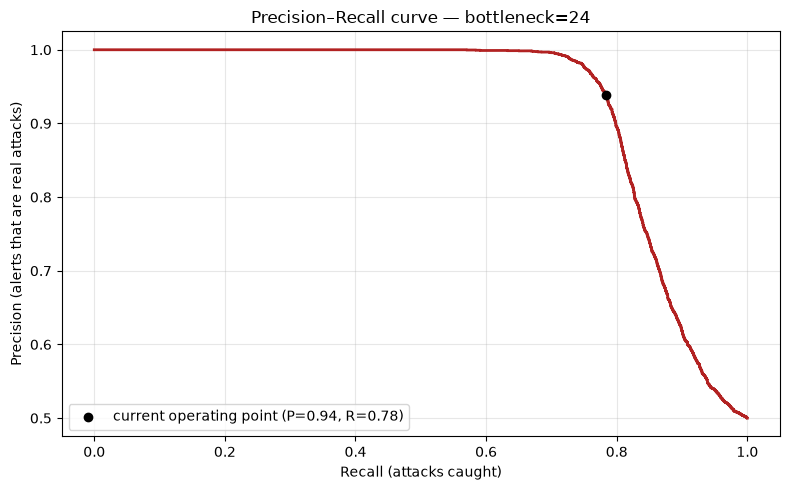

In [56]:
from sklearn.metrics import precision_recall_curve, precision_score, recall_score

prec, rec, _ = precision_recall_curve(y_test, test_err)

p_now = precision_score(y_test, y_pred, zero_division=0)
r_now = recall_score(y_test, y_pred, zero_division=0)

plt.figure(figsize=(8, 5))
plt.plot(rec, prec, color="firebrick", lw=2)
plt.scatter([r_now], [p_now], color="black", zorder=5,
            label=f"current operating point (P={p_now:.2f}, R={r_now:.2f})")
plt.xlabel("Recall (attacks caught)")
plt.ylabel("Precision (alerts that are real attacks)")
plt.title(f"Precision–Recall curve — bottleneck={MAIN_CONFIG['bottleneck']}")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

#### per-attack type breakdown

In [57]:
iot_test["pred"]   = y_pred
iot_test["error"]  = test_err
iot_test["caught"] = (iot_test["pred"] == 1)

per_type = (iot_test[iot_test["attack"] == 1]
            .groupby("subcategory")
            .agg(n=("caught", "size"),
                 caught=("caught", "sum"),
                 mean_err=("error", "mean"))
            .assign(recall=lambda d: d["caught"] / d["n"])
            .sort_values("recall", ascending=False))

print(per_type.to_string())

                   n  caught  mean_err  recall
subcategory                                   
Service_Scan     625     625  0.466248  1.0000
OS_Fingerprint   625     625  0.936609  1.0000
Keylogging       625     468  0.341559  0.7488
UDP             1250     895  0.286876  0.7160
TCP             1250     877  0.304464  0.7016
HTTP             625     427  0.223447  0.6832


---

### Baseline models (Forest, SVM, RF)

1. Isolation Forest - unsupervised tree ensemble

2. Simple one-class Support Vector Machine (check if a clean boundary already exists in the data).

3. Superised Random Forest : compare performance gain if we used a labeled set instead.



In [58]:
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.svm import OneClassSVM
from sklearn.metrics import roc_auc_score, f1_score, recall_score, precision_score
from sklearn.model_selection import train_test_split

X_te_enc = datasets["encoded"]["X_test"]
y_te     = datasets["encoded"]["y_test"]

def metrics_from_scores(y_true, scores, threshold):
    yp = (scores > threshold).astype(int)
    return {
        "auc":       float(roc_auc_score(y_true, scores)),
        "f1":        float(f1_score(y_true, yp, zero_division=0)),
        "recall":    float(recall_score(y_true, yp, zero_division=0)),
        "precision": float(precision_score(y_true, yp, zero_division=0)),
    }

baseline_results = {}

# ── 1. Isolation Forest (unsupervised, benign-only) ─────────────────────────
print("Training Isolation Forest...")
iso = IsolationForest(contamination=0.05, n_estimators=200, random_state=42, n_jobs=-1)
iso.fit(X_tr)
iso_scores_va = -iso.score_samples(X_va)
iso_scores_te = -iso.score_samples(X_te_enc)
iso_thr = np.percentile(iso_scores_va, 95)
baseline_results["IsolationForest"] = metrics_from_scores(y_te, iso_scores_te, iso_thr)

# ── 2. One-Class SVM (unsupervised, benign-only) ────────────────────────────
print("Training One-Class SVM...")
ocsvm = OneClassSVM(nu=0.05, kernel="rbf", gamma="scale")
ocsvm.fit(X_tr)
svm_scores_va = -ocsvm.score_samples(X_va)
svm_scores_te = -ocsvm.score_samples(X_te_enc)
svm_thr = np.percentile(svm_scores_va, 95)
baseline_results["OneClassSVM"] = metrics_from_scores(y_te, svm_scores_te, svm_thr)

# ── 3. Supervised RF (oracle — uses labels, not deployable) ─────────────────
print("Training supervised Random Forest (oracle)...")
X_lab_tr, X_lab_ev, y_lab_tr, y_lab_ev = train_test_split(
    X_te_enc, y_te, train_size=0.5, random_state=42, stratify=y_te
)
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_lab_tr, y_lab_tr)
rf_scores_ev = rf.predict_proba(X_lab_ev)[:, 1]
baseline_results["SupervisedRF_oracle"] = metrics_from_scores(y_lab_ev, rf_scores_ev, 0.5)

# ── Print ────────────────────────────────────────────────────────────────────
print("\nBaseline comparison:")
print(f"{'Model':>26} {'AUC':>8} {'F1':>8} {'Recall':>8} {'Precision':>10}")
for name, m in baseline_results.items():
    print(f"  {name:>24}  {m['auc']:.4f}  {m['f1']:.3f}  {m['recall']:.3f}  {m['precision']:.3f}")

datasets["baselines"] = baseline_results
save_datasets()

Training Isolation Forest...
Training One-Class SVM...
Training supervised Random Forest (oracle)...

Baseline comparison:
                     Model      AUC       F1   Recall  Precision
           IsolationForest  0.6375  0.282  0.173  0.774
               OneClassSVM  0.8577  0.822  0.734  0.934
       SupervisedRF_oracle  0.9856  0.929  0.892  0.969
saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/datasets.pkl  (24.77 MB)


### bottleneck sweep

[1/5] bottleneck=4
  AUC=0.8541  F1=0.596  recall=0.446  gap=0.00315  epochs=95
[2/5] bottleneck=8
  AUC=0.8292  F1=0.682  recall=0.543  gap=0.00169  epochs=75
[3/5] bottleneck=16
  AUC=0.8359  F1=0.765  recall=0.650  gap=-0.00001  epochs=100
[4/5] bottleneck=24
  AUC=0.8899  F1=0.854  recall=0.782  gap=0.00014  epochs=82
[5/5] bottleneck=32
  AUC=0.8803  F1=0.815  recall=0.721  gap=0.00020  epochs=77

=== Bottleneck sweep ===
 bottleneck      auc       f1  recall  precision  train_val_gap  epochs_run
          4 0.854069 0.596496  0.4460   0.900283       0.003147          95
          8 0.829177 0.681989  0.5430   0.916610       0.001694          75
         16 0.835936 0.764595  0.6496   0.929062      -0.000008         100
         24 0.889896 0.854490  0.7822   0.941502       0.000139          82
         32 0.880314 0.814555  0.7208   0.936347       0.000198          77


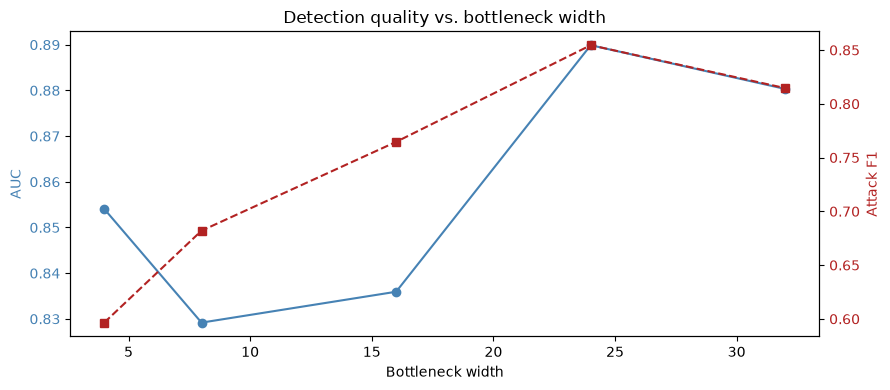

saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/datasets.pkl  (24.77 MB)


In [59]:
sweep_results = []
sweep_configs = [
    {"bottleneck":  4, "lr": 1e-3, "batch_size": 256, "epochs": 100, "patience": 10},
    {"bottleneck":  8, "lr": 1e-3, "batch_size": 256, "epochs": 100, "patience": 10},
    {"bottleneck": 16, "lr": 1e-3, "batch_size": 256, "epochs": 100, "patience": 10},
    {"bottleneck": 24, "lr": 1e-3, "batch_size": 256, "epochs": 100, "patience": 10},
    {"bottleneck": 32, "lr": 1e-3, "batch_size": 256, "epochs": 100, "patience": 10},
]

def recon_errors(m, X):
    m.eval()
    with torch.no_grad():
        X_t = torch.from_numpy(X)
        return ((m(X_t) - X_t) ** 2).mean(dim=1).numpy()

for i, cfg in enumerate(sweep_configs, 1):
    print(f"[{i}/{len(sweep_configs)}] bottleneck={cfg['bottleneck']}")
    m, h, tm = train_autoencoder(X_tr, X_va, cfg, verbose=False)
    val_err_k  = recon_errors(m, X_va)
    test_err_k = recon_errors(m, X_te_enc)
    thr_k      = np.percentile(val_err_k, 95)
    mm = metrics_from_scores(y_te, test_err_k, thr_k)
    mm.update({
        "bottleneck":    cfg["bottleneck"],
        "epochs_run":    tm["epochs_run"],
        "best_val":      round(tm["best_val"], 6),
        "train_val_gap": round(tm["train_val_gap"], 6),
    })
    sweep_results.append(mm)
    print(f"  AUC={mm['auc']:.4f}  F1={mm['f1']:.3f}  recall={mm['recall']:.3f}  "
          f"gap={mm['train_val_gap']:.5f}  epochs={mm['epochs_run']}")

sweep_df = pd.DataFrame(sweep_results)[
    ["bottleneck", "auc", "f1", "recall", "precision", "train_val_gap", "epochs_run"]
].sort_values("bottleneck")

print("\n=== Bottleneck sweep ===")
print(sweep_df.to_string(index=False))

# Plot AUC and F1 vs bottleneck
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(sweep_df["bottleneck"], sweep_df["auc"], "o-", color="steelblue", label="AUC")
ax1.set_xlabel("Bottleneck width"); ax1.set_ylabel("AUC", color="steelblue")
ax1.tick_params(axis="y", labelcolor="steelblue")

ax2 = ax1.twinx()
ax2.plot(sweep_df["bottleneck"], sweep_df["f1"], "s--", color="firebrick", label="F1")
ax2.set_ylabel("Attack F1", color="firebrick")
ax2.tick_params(axis="y", labelcolor="firebrick")

plt.title("Detection quality vs. bottleneck width")
plt.tight_layout(); plt.show()

sweep_df.to_csv(STORE_DIR / "bottleneck_sweep.csv", index=False)
datasets["sweep"] = sweep_df.to_dict()
save_datasets()

Notes :
- bottleneck=24 is the clear winner
- leads on AUC, F1, Recall, 
- change MAIN_CONFIG["bottleneck"] to 24 and run the main cells again !

Bottleneck :
- Usually we think that a small bottleneck is better, but that's not always the case, the model needs enough room to reconstruct the data and capture patterns correctly, but not too wide that it starts reconstructing attacks too.





### Overfitting analysis


For a semi-supervised autoencoder, overfitting means: **the model reconstructs
training benign flows almost perfectly, but performs worse on new benign flows
(validation)**. Two consequences for anomaly detection:

1. **The threshold rises.** 95th percentile of `val_err` moves up → fewer test rows
   cross it → recall drops. Overfitting **hurts** detection.
2. **Feature memorisation.** The encoder learns features unique to the training split
   (specific device quirks, specific timestamps) that don't generalise.

The `train_val_gap` column in the sweep table quantifies this:

- **gap < 10% of best_val** → healthy generalisation
- **gap 10–30%** → mild overfitting, watch for it in longer runs
- **gap > 30%** → overfitting; remedies: shrink bottleneck, increase patience,
  add more training data, or add weight decay.

Look at the sweep table: is any bottleneck in the danger zone? If yes, mark it.
If no, report "no overfitting observed at any tested configuration, likely because
the effective dataset (27 k rows) is large relative to the model capacity
(26 input features)."

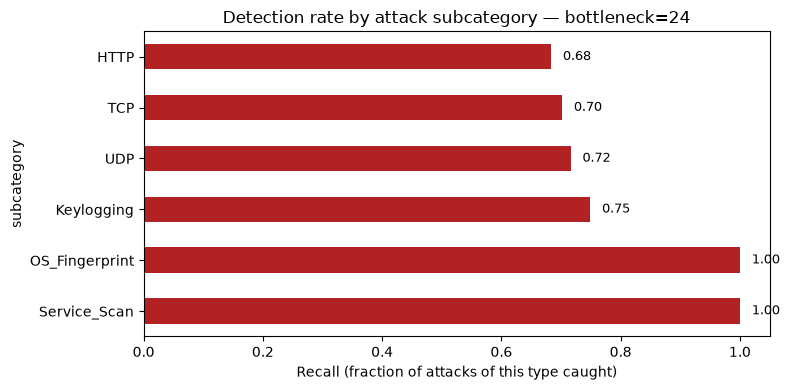

In [60]:
# Per-attack bar chart
ax = per_type["recall"].plot(kind="barh", color="firebrick", figsize=(8, 4))
ax.set_xlabel("Recall (fraction of attacks of this type caught)")
ax.set_title(f"Detection rate by attack subcategory — bottleneck={MAIN_CONFIG['bottleneck']}")
ax.set_xlim(0, 1.05)
for i, (idx, row) in enumerate(per_type.iterrows()):
    ax.text(row["recall"] + 0.02, i, f"{row['recall']:.2f}", va="center", fontsize=9)
plt.tight_layout(); plt.show()

### Comparison table

In [61]:
best_ae = sweep_df.loc[sweep_df["auc"].idxmax()]

final_rows = [
    {"model": f"AE bottleneck={int(best_ae['bottleneck'])}",
     **{k: round(best_ae[k], 4) for k in ["auc", "f1", "recall", "precision"]}},
    {"model": "Isolation Forest",
     **{k: round(baseline_results["IsolationForest"][k], 4) for k in ["auc", "f1", "recall", "precision"]}},
    {"model": "One-Class SVM",
     **{k: round(baseline_results["OneClassSVM"][k], 4) for k in ["auc", "f1", "recall", "precision"]}},
    {"model": "Supervised RF (oracle)",
     **{k: round(baseline_results["SupervisedRF_oracle"][k], 4) for k in ["auc", "f1", "recall", "precision"]}},
]
final_df = pd.DataFrame(final_rows)

print("=== Final comparison ===")
print(final_df.to_string(index=False))
final_df.to_csv(STORE_DIR / "final_comparison.csv", index=False)
print(f"saved → {STORE_DIR / 'final_comparison.csv'}")

=== Final comparison ===
                 model    auc     f1  recall  precision
      AE bottleneck=24 0.8899 0.8545  0.7822     0.9415
      Isolation Forest 0.6375 0.2823  0.1726     0.7740
         One-Class SVM 0.8577 0.8218  0.7336     0.9340
Supervised RF (oracle) 0.9856 0.9287  0.8916     0.9691
saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/final_comparison.csv


In [63]:
# Final comparison
rows = []

# 1. Baselines
for key, label in [
    ("IsolationForest",     "Isolation Forest"),
    ("OneClassSVM",         "One-Class SVM"),
    ("SupervisedRF_oracle", "Supervised RF (oracle)"),
]:
    m = baseline_results[key]
    rows.append({
        "Model":     label,
        "AUC":       round(m["auc"], 4),
        "F1":        round(m["f1"], 3),
        "Recall":    round(m["recall"], 3),
        "Precision": round(m["precision"], 3),
    })

# 2. AE — one row per bottleneck, mark the best
best_bn = int(sweep_df.loc[sweep_df["auc"].idxmax(), "bottleneck"])
for _, r in sweep_df.iterrows():
    label = f"AE — bottleneck={int(r['bottleneck'])}"
    if int(r["bottleneck"]) == best_bn:
        label += "  BEST"
    rows.append({
        "Model":     label,
        "AUC":       round(r["auc"], 4),
        "F1":        round(r["f1"], 3),
        "Recall":    round(r["recall"], 3),
        "Precision": round(r["precision"], 3),
    })

final_table = pd.DataFrame(rows)

# ── Display in the notebook ─────────────────────────────────────────────────
print("=" * 76)
print(f"FINAL RESULTS  —  {len(final_table)} models  —  5% FPR target")
print(f"Best AE config: bottleneck={best_bn}")
print("=" * 76)
display(final_table)

# ── Save as CSV (for downstream analysis) ───────────────────────────────────
csv_path = STORE_DIR / "final_comparison.csv"
final_table.to_csv(csv_path, index=False)
print(f"\nsaved → {csv_path}")

# ── Save as markdown (for pasting into the report) ──────────────────────────
md_lines = [
    "| Model | AUC | F1 | Recall | Precision |",
    "|---|---|---|---|---|",
]
for _, r in final_table.iterrows():
    md_lines.append(
        f"| {r['Model']} | {r['AUC']} | {r['F1']} | "
        f"{r['Recall']} | {r['Precision']} |"
    )
md_str = "\n".join(md_lines)

md_path = STORE_DIR / "final_comparison.md"
with open(md_path, "w") as f:
    f.write("# Final results — all models compared\n\n")
    f.write(
        "Operating point: 95th-percentile threshold on benign validation "
        "(target FPR = 5%). Supervised RF uses attack labels — included as "
        "an **oracle upper bound**, not a deployable baseline.\n\n"
    )
    f.write(md_str)
    f.write(f"\n\n = best AE configuration (selected by AUC): bottleneck={best_bn}.\n")
print(f"saved → {md_path}")

# ── Store in datasets for consistency ───────────────────────────────────────
datasets["final_comparison"] = final_table
save_datasets()

FINAL RESULTS  —  8 models  —  5% FPR target
Best AE config: bottleneck=24


,Model,AUC,F1,Recall,Precision
0,Isolation Forest,0.6375,0.282,0.173,0.774
1,One-Class SVM,0.8577,0.822,0.734,0.934
2,Supervised RF (oracle),0.9856,0.929,0.892,0.969
3,AE — bottleneck=4,0.8541,0.596,0.446,0.900
4,AE — bottleneck=8,0.8292,0.682,0.543,0.917
5,AE — bottleneck=16,0.8359,0.765,0.650,0.929
6,AE — bottleneck=24 BEST,0.8899,0.854,0.782,0.942
7,AE — bottleneck=32,0.8803,0.815,0.721,0.936



saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/final_comparison.csv
saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/final_comparison.md
saved → /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/processed/datasets.pkl  (24.77 MB)




Isolation Forest :
-  AUC 0.638 means it's barely better than random (0.5 = coin flip).
- Isolation Forest splits on random features at random thresholds. 
- One one-hot encoded, it can only make one type of split.
- IF is very limited with these one-hot-encoded categorical features, which make up 8 of the 26 encoded features.




One-Class SVM :
- Performed really well : AUC 0.858, F1 0.822
- OC-SVM with an RBF kernel is a strong tabular method. It learns a smooth boundary around the benign data in kernel space. On 26 features with 27k rows, a kernel method can capture most of the structure without the complexity of deep learning.
- 




Supervised RF (oracle) : 
- AUC 0.986, F1 0.929
- Labelled data allowed us to gain +10 AUC points, which is quitre significant
- so the cost of being able to deploy without labelled attack data is those 10 points




AE — bottleneck=4	0.8541	0.596	0.446	0.900
4	AE — bottleneck=8	0.8292	0.682	0.543	0.917
5	AE — bottleneck=16	0.8359	0.765	0.650	0.929
6	AE — bottleneck=24  BEST	0.8899	0.854	0.782	0.942
7	AE — bottleneck=32







## Takeaways from this smoke-test

1. The pipeline pattern works. raw → cleaned → semisup → encoded → AE → threshold → eval. Every stage is a dict in datasets, every stage is saved, every stage has an alignment assert. Copy this structure over for AIT.

2. The AE learns something useful on network flow data. 0.89 AUC on a balanced test set — meaningfully better than random, with clean separation in the error distribution. The architecture choice (symmetric MLP with adjustable bottleneck) is fine.

3. Threshold calibration from benign validation alone works. 95th percentile of val_err produced the expected 5% FPR, and the model discriminated at that operating point. This is the core semi-supervised trick.

4. A bottleneck sweep is 3 minutes and gives a defensible hyperparameter choice. Worth doing on AIT too.

5. Baselines are cheap to add and give context. Isolation Forest and OC-SVM took ~2 minutes total to add. The RF "oracle" took 30 seconds. Doing the same on AIT costs almost nothing.

--- 
end